In [1146]:
import pandas as pd
import numpy as np
# Statistical visualization
import matplotlib.pyplot as plt
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1147]:
df=pd.read_csv('/content/drive/MyDrive/Retail_Pulse_Project/1_Data/RetailPulse_500000_rows.csv')
df.shape #(801600, 13)
df.head(10)
df.tail()
df.sample(10)

,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment
281799,586683,40,Male,South,Grocery,30636.30,7.0,8462.75,2025-03-15,5.27,0.2109,0.0238,Budget
54454,164261,32,Female,East,Clothing,56375.29,18.0,22460.30,2025-12-30,5.20,0.2109,0.0965,Premium
280731,578479,23,Female,West,Sports,176661.38,9.0,31063.75,2025-10-30,7.28,0.3780,0.1237,Regular
342208,134349,38,Female,Central,Beauty,39275.04,5.0,6427.53,2025-12-17,1.40,0.5507,0.0710,Regular
24036,349997,34,Female,South,Home & Kitchen,90534.37,16.0,20434.65,2025-10-02,5.24,0.0962,0.1845,Premium
285370,566046,32,Male,West,Clothing,39930.51,7.0,8039.06,2025-10-27,3.97,0.4600,0.0482,Regular
166595,566304,33,Female,East,Clothing,87583.58,13.0,14555.70,2025-12-30,4.68,0.5471,0.0600,Regular
134518,474950,37,Male,East,Grocery,18000.00,5.0,3543.17,2025-11-24,11.12,0.4198,0.1054,Regular
447481,534736,25,Female,Central,Beauty,66934.35,8.0,17873.35,2025-12-17,11.47,0.3763,0.0389,Regular
185263,225902,40,Female,East,Sports,35210.71,7.0,7414.88,2025-09-27,5.01,0.0824,0.0381,Regular


In [1148]:
df["LastPurchaseDate"] = pd.to_datetime(
    df["LastPurchaseDate"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [1149]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   CustomerID            500000 non-null  int64         
 1   Age                   500000 non-null  int64         
 2   Gender                497001 non-null  object        
 3   Region                496504 non-null  object        
 4   ProductCategory       497001 non-null  object        
 5   AnnualIncome          495002 non-null  float64       
 6   PurchaseFrequency     495998 non-null  float64       
 7   AnnualPurchaseAmount  500000 non-null  float64       
 8   LastPurchaseDate      500000 non-null  datetime64[ns]
 9   CustomerTenure        500000 non-null  float64       
 10  DiscountUsage         494997 non-null  float64       
 11  ReturnRate            496500 non-null  float64       
 12  CustomerSegment       500000 non-null  object        
dtyp

In [1150]:
df.describe()

,CustomerID,Age,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate
count,500000.000000,500000.000000,495002.000000,495998.000000,500000.000000,500000,500000.000000,494997.000000,496500.000000
mean,349499.546422,40.856144,67404.824695,8.596408,12884.542060,2025-11-01 10:31:07.564800256,4.243120,0.339433,0.085718
min,100001.000000,18.000000,18000.000000,1.000000,565.000000,2024-12-31 00:00:00,0.250000,0.005100,0.000000
25%,224736.750000,32.000000,43434.195000,5.000000,6763.360000,2025-10-15 00:00:00,2.270000,0.187200,0.049700
50%,349483.500000,40.000000,60097.425000,7.000000,10392.100000,2025-11-21 00:00:00,3.700000,0.309500,0.075800
75%,474260.250000,49.000000,83034.477500,11.000000,16047.522500,2025-12-12 00:00:00,5.640000,0.466800,0.111600
max,599000.000000,70.000000,350000.000000,55.000000,316973.080000,2025-12-30 00:00:00,14.800000,0.980000,0.524700
std,144051.571449,11.756830,34246.285517,5.554789,9422.420371,NaN,2.646383,0.190285,0.049652


In [1151]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Region', 'ProductCategory',
       'AnnualIncome', 'PurchaseFrequency', 'AnnualPurchaseAmount',
       'LastPurchaseDate', 'CustomerTenure', 'DiscountUsage', 'ReturnRate',
       'CustomerSegment'],
      dtype='object')

In [1152]:
num=df.select_dtypes(include="number").columns
cat=df.select_dtypes(include="object").columns
print(num)
print(cat)

Index(['CustomerID', 'Age', 'AnnualIncome', 'PurchaseFrequency',
       'AnnualPurchaseAmount', 'CustomerTenure', 'DiscountUsage',
       'ReturnRate'],
      dtype='object')
Index(['Gender', 'Region', 'ProductCategory', 'CustomerSegment'], dtype='object')


**Numerical Column**

In [1153]:
# df.isnull().mean()*100
df.select_dtypes(include="number").isnull().sum()

,0
CustomerID,0
Age,0
AnnualIncome,4998
PurchaseFrequency,4002
AnnualPurchaseAmount,0
CustomerTenure,0
DiscountUsage,5003
ReturnRate,3500


In [1154]:
null_count=df.select_dtypes(include=["number"]).isnull().sum()
null_count[null_count>0]

,0
AnnualIncome,4998
PurchaseFrequency,4002
DiscountUsage,5003
ReturnRate,3500


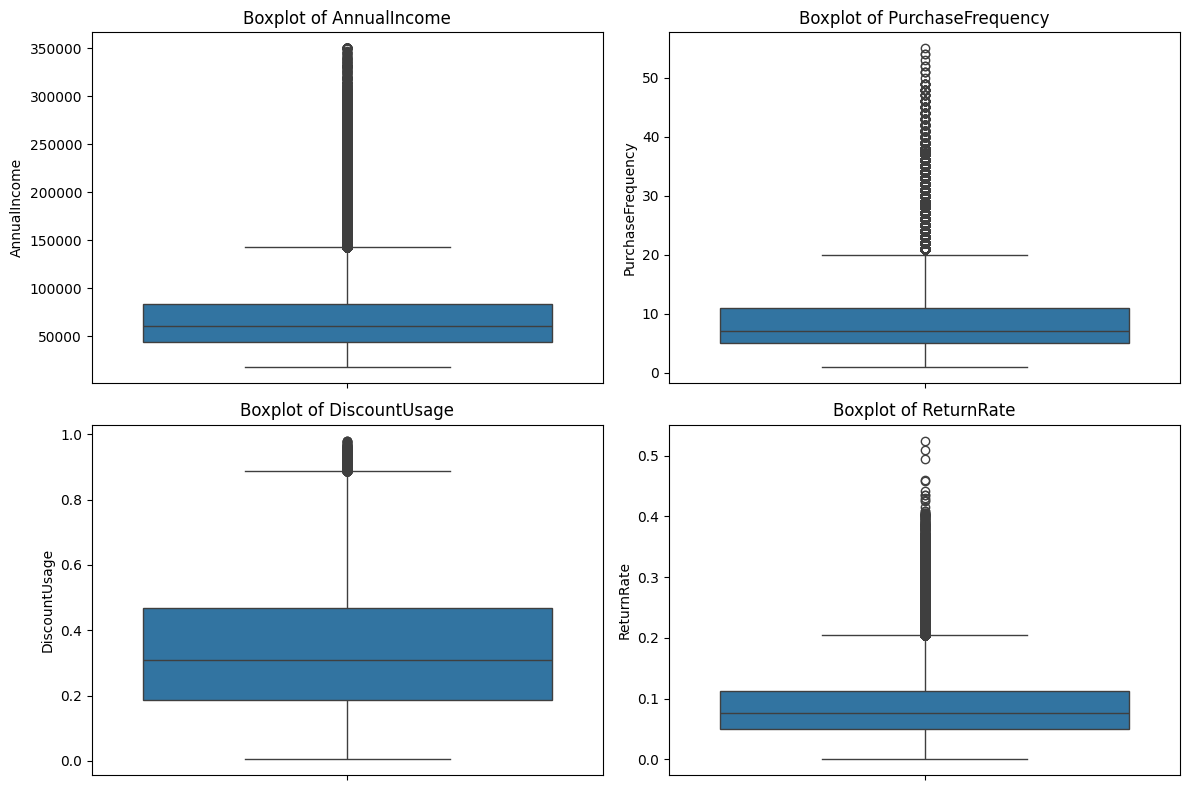

In [1155]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    "AnnualIncome",
    "PurchaseFrequency",
    "DiscountUsage",
    "ReturnRate"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [1156]:
num_cols = [
    "AnnualIncome",
    "PurchaseFrequency",
    "DiscountUsage",
    "ReturnRate"
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

**Categorical**

In [1157]:
cat

Index(['Gender', 'Region', 'ProductCategory', 'CustomerSegment'], dtype='object')

In [1158]:
df.select_dtypes(include="object").isnull().sum()

,0
Gender,2999
Region,3496
ProductCategory,2999
CustomerSegment,0


In [1159]:
null_count=df.select_dtypes(include=["object"]).isnull().sum()
null_count[null_count>0]

,0
Gender,2999
Region,3496
ProductCategory,2999


In [1182]:
df["Gender"].unique()

array(['male', 'female', 'unknown'], dtype=object)

In [1161]:
for col in cat:
    df[col] = df[col].str.strip().str.lower()

In [1162]:
df["Gender"] = df["Gender"].replace("other", "unknown")

In [1163]:
df["Region"].unique()

array(['north', 'east', 'central', 'south', 'west', nan], dtype=object)

In [1164]:
df["ProductCategory"].unique()

array(['beauty', 'clothing', 'electronics', 'home & kitchen', 'grocery',
       'sports', nan, 'home and kitchen'], dtype=object)

In [1165]:
df["ProductCategory"] = df["ProductCategory"].replace({
    "home and kitchen": "home & kitchen"
})

In [1166]:
df["CustomerSegment"].unique()

array(['regular', 'budget', 'premium'], dtype=object)

In [1167]:
for col in cat:
    df[col] = df[col].fillna("unknown")

**Add new with existing feature**

In [1168]:
df["LastPurchaseDate"].dtype

dtype('<M8[ns]')

In [1169]:
reference_date = pd.Timestamp("2025-12-31")
df["Recency"] = (
    reference_date - df["LastPurchaseDate"]
).dt.days
df.drop("LastPurchaseDate", axis=1, inplace=True)

In [1184]:
df["Recency"].sample(5)

,Recency
74670,1
48124,60
422149,59
373473,162
467250,25


**Duplicate**

In [1171]:
# df.duplicated().sum()  #1000
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [1172]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499000 entries, 0 to 498999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CustomerID            499000 non-null  int64  
 1   Age                   499000 non-null  int64  
 2   Gender                499000 non-null  object 
 3   Region                499000 non-null  object 
 4   ProductCategory       499000 non-null  object 
 5   AnnualIncome          499000 non-null  float64
 6   PurchaseFrequency     499000 non-null  float64
 7   AnnualPurchaseAmount  499000 non-null  float64
 8   CustomerTenure        499000 non-null  float64
 9   DiscountUsage         499000 non-null  float64
 10  ReturnRate            499000 non-null  float64
 11  CustomerSegment       499000 non-null  object 
 12  Recency               499000 non-null  int64  
dtypes: float64(6), int64(3), object(4)
memory usage: 49.5+ MB


In [1183]:
# df.to_csv("After_clean_retailpulse.csv", index=False)